# Figure S4b–c — program CRT calibration and biological-replicate effect concordance

This notebook generates:

- **Panel S4b:** empirical CRT Q–Q plots for real target–program tests and matched non-targeting pseudo-target tests at D0–D3.
- **Panel S4c:** biological-replicate comparisons of matched target–program beta estimates after the specified support and pooled-significance filters.

By default, the notebook reads existing numerical CRT and replicate-beta results and regenerates the plots. Set `RECOMPUTE_CRT=True` to recompute the numerical results from the configured inputs using `B=10000` for the full-day CRT and `B_REP=127` for replicate beta estimation.


In [1]:
from pathlib import Path
import sys, os, json
from IPython.display import display
REPO_ROOT = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents) if (p / "src" / "cc_perturbseq").is_dir()), None)
if REPO_ROOT is None:
    raise FileNotFoundError("Open this notebook inside the repository checkout.")
if str(REPO_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "src"))
from cc_perturbseq.figure_notebook import initialize_figure, load_figure_manifest, get_path, panel_directory, write_receipt

import pandas as pd
from cc_perturbseq.figure_s04_panels import *
from cc_perturbseq import crt_qq_backend as qqb
from cc_perturbseq.figure_s04_runtime import build_crt_argv, launch_crt_recomputation
ctx = initialize_figure(load_figure_manifest("Figure_S04"), require_inputs=False)
PANEL_B_DIR, PANEL_C_DIR = panel_directory(ctx,"b"), panel_directory(ctx,"c")
# Replot from numerical results, never from old figure files. Enable raw CRT
# recomputation explicitly when the per-day results/beta matrices need rebuilding.
RECOMPUTE_CRT = False
# Set to "replicates" to resume a completed full-day export after a replicate failure.
# Its prior runtime/configuration/mapping records are verified before any output is changed.
CRT_STAGE = "all"
# Retain original gene/control group names and RNG inputs for manuscript reproduction.
GUIDE_MAPPING_POLICY = "source_names"
# Original S4 CRT used sc-dl; R-SCEPTRE guide assignment is a separate upstream step.
# Explicit override: /oak/stanford/groups/engreitz/Users/tri/envs/sc-dl/bin/python
CRT_PYTHON = os.environ.get("CCPERTURBSEQ_S4_PYTHON", sys.executable)
print("Notebook Python:", sys.executable)
print("CRT worker Python:", CRT_PYTHON)
DAYS = ["d0","d1","d2","d3"]
K, DENSITY_THRESHOLD, B = 50, "0_2", 10000
NTC_LABELS = ["SAFE","non-targeting","NTC"]
N_JOBS = int(os.environ.get("SLURM_CPUS_PER_TASK","4"))
INPUT_MODEL_ROOT = Path(os.environ.get("CCPERTURBSEQ_S4_RESULTS", "/oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/iPSC_EC_QQ_full_covariates_with_replicate_correlation_bundle/results/ipsc_ec_qq_exports_full_covariates/k_50.dt_0_2"))
PROGRAMDE_ROOT = Path(qqb.DEFAULT_PROGRAMDE_ROOT)
DATA_DIR, CNMF_DIR = Path(qqb.DEFAULT_DATA_DIR), Path(qqb.DEFAULT_CNMF_DIR)
GUIDE_LONG_TEMPLATE = qqb.DEFAULT_GUIDE_LONG_TEMPLATE
GUIDE_METADATA_TSV = get_path(ctx["paths"],"ccperturbseq.target_metadata")
RECOMPUTED_ROOT = ctx["output_dir"] / "recomputed_crt"
print("Numerical inputs:",INPUT_MODEL_ROOT)
print("Recompute raw CRT:",RECOMPUTE_CRT)

# S4c settings from the FINAL executed source cell, not the earlier unfiltered panel.
# S4b uses empirical p-values; S4c's archived selection preferred skew p-values.
POOLED_PVALUE_TYPE = "skew"
POOLED_Q_CUTOFF = 0.10
MIN_TARGET_CELLS_PER_REP = 20
TARGET_COUNTS_CSV = None  # or an explicit DIAGNOSTIC_target_cell_counts_by_replicate.csv


Notebook Python: /oak/stanford/groups/engreitz/Users/tri/envs/sc-dl/bin/python
CRT worker Python: /oak/stanford/groups/engreitz/Users/tri/envs/sc-dl/bin/python
Numerical inputs: /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/iPSC_EC_QQ_full_covariates_with_replicate_correlation_bundle/results/ipsc_ec_qq_exports_full_covariates/k_50.dt_0_2
Recompute raw CRT: False


## Numerical inputs and runtime

The analysis uses saved guide-assignment tables produced upstream and runs the program-level CRT in Python. It does not rerun guide assignment.

When `RECOMPUTE_CRT=True`, the notebook validates the command-line arguments, selected Python interpreter, programDE import location, and all requested day-specific inputs before starting computation. Full-day CRT and replicate beta estimation run in the same selected interpreter. Set `CRT_PYTHON` to an explicit interpreter when the notebook kernel and CRT environment differ.

Runtime logs and input/version records are written to `recomputed_crt/s4_crt.log` and `recomputed_crt/s4_crt_runtime.json`. Any worker failure stops subsequent plotting.


### Replicate-output settings and resuming

Replicate beta extraction uses `calibrate_skew_normal=False`, `return_raw_pvals=False`, and `return_skew_normal=False`; `betas_df` is returned directly by programDE. The optional no-skew full-day path reads empirical results from `pvals_df`.

After a full-day export has completed, set `RECOMPUTE_CRT=True` and `CRT_STAGE="replicates"` to run only replicate estimation. The output directory, scientific settings, inputs, and guide mapping must match the completed full-day run. Use `CRT_STAGE="all"` for a new or changed analysis.

`GUIDE_MAPPING_POLICY="source_names"` preserves the target and control labels used by the analysis while auditing labels from the v43 guide-metadata table. `GUIDE_MAPPING_POLICY="metadata"` is an explicit alternative that uses the metadata target labels and requires both stages to be regenerated when mappings change.


In [2]:
if RECOMPUTE_CRT:
    argv = build_crt_argv(
        programde_root=PROGRAMDE_ROOT, data_dir=DATA_DIR, cnmf_dir=CNMF_DIR,
        guide_long_template=GUIDE_LONG_TEMPLATE, guide_metadata_tsv=GUIDE_METADATA_TSV,
        output_dir=RECOMPUTED_ROOT, days=DAYS, k=K,
        density_threshold=DENSITY_THRESHOLD, B=B, n_jobs=N_JOBS,
        ntc_labels=NTC_LABELS, overwrite=True, guide_mapping_policy=GUIDE_MAPPING_POLICY,
    )
    # Uses the source parser's --guide-long-csv-template spelling. It is parsed
    # before a child process is started; Jupyter's own argv is never consumed.
    runtime_report = launch_crt_recomputation(argv, python_executable=CRT_PYTHON, stage=CRT_STAGE)
    display(runtime_report)
    INPUT_MODEL_ROOT = RECOMPUTED_ROOT / qqb.model_tag(K, qqb.normalize_density_token(DENSITY_THRESHOLD))

qq_csv = INPUT_MODEL_ROOT / "all_days_QQ_points.csv"
manifest_path = INPUT_MODEL_ROOT / "biological_replicate_effects/replicate_beta_manifest.csv"
for path in (qq_csv, manifest_path):
    if not path.is_file() or path.stat().st_size == 0:
        raise FileNotFoundError(f"Missing numerical S4 input: {path}. Set INPUT_MODEL_ROOT to the results directory or enable RECOMPUTE_CRT. No previous notebook/figure is needed.")
qq_points = pd.read_csv(qq_csv)
# Recalculate Q-Q coordinates using the original backend rank formula.
if "pvalue" in qq_points:
    grouping = [c for c in ["day","pvalue_type","series_type"] if c in qq_points]
    qq_points = pd.concat([qqb.add_qq_columns(g.copy()) for _,g in qq_points.groupby(grouping,sort=False)],ignore_index=True)
qq_points.to_csv(PANEL_B_DIR / "all_days_QQ_points.csv",index=False)
manifest = pd.read_csv(manifest_path)
manifest = manifest.loc[manifest["status"].isin(["written","existing"]) & manifest["beta_path"].notna()].copy()
# Only explicit relative paths or the exact source basename in its day folder
# are relocated; never scan arbitrary beta tables or copy finished figures.
for index,row in manifest.iterrows():
    recorded = Path(str(row["beta_path"]))
    candidates = [recorded] if recorded.is_absolute() else [manifest_path.parent / recorded, INPUT_MODEL_ROOT / recorded]
    candidates += [manifest_path.parent / "betas_by_replicate" / str(row["day"]) / recorded.name]
    found = next((p for p in candidates if p.is_file() and p.stat().st_size),None)
    if found is None:
        raise FileNotFoundError(f"Missing beta matrix: {recorded}; checked {candidates}")
    manifest.loc[index,"beta_path"] = str(found.resolve())
if manifest.empty:
    raise ValueError("No usable numerical beta matrices in replicate manifest.")
display(manifest)


/tmp/ipykernel_18111/1311401739.py:20: DtypeWarning: Columns (6) have mixed types. Specify dtype option on import or set low_memory=False.


,day,biological_sample,status,n_cells,beta_path,metadata_path
0,d0,d0_rep1,written,17488,/oak/stanford/groups/engreitz/Users/tri/CodeBa...,results/ipsc_ec_qq_exports_full_covariates/k_5...
1,d0,d0_rep2,written,21121,/oak/stanford/groups/engreitz/Users/tri/CodeBa...,results/ipsc_ec_qq_exports_full_covariates/k_5...
2,d1,d1_rep1,written,5856,/oak/stanford/groups/engreitz/Users/tri/CodeBa...,results/ipsc_ec_qq_exports_full_covariates/k_5...
3,d1,d1_rep2,written,11069,/oak/stanford/groups/engreitz/Users/tri/CodeBa...,results/ipsc_ec_qq_exports_full_covariates/k_5...
4,d2,d2_rep1,written,10895,/oak/stanford/groups/engreitz/Users/tri/CodeBa...,results/ipsc_ec_qq_exports_full_covariates/k_5...
5,d2,d2_rep2,written,11085,/oak/stanford/groups/engreitz/Users/tri/CodeBa...,results/ipsc_ec_qq_exports_full_covariates/k_5...
6,d3,d3_rep1,written,21377,/oak/stanford/groups/engreitz/Users/tri/CodeBa...,results/ipsc_ec_qq_exports_full_covariates/k_5...
7,d3,d3_rep2,written,22725,/oak/stanford/groups/engreitz/Users/tri/CodeBa...,results/ipsc_ec_qq_exports_full_covariates/k_5...


## S4b — empirical Q–Q plots

For each differentiation day, observed empirical CRT p values are compared with the uniform expectation for real target–program tests and non-targeting pseudo-target tests.


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


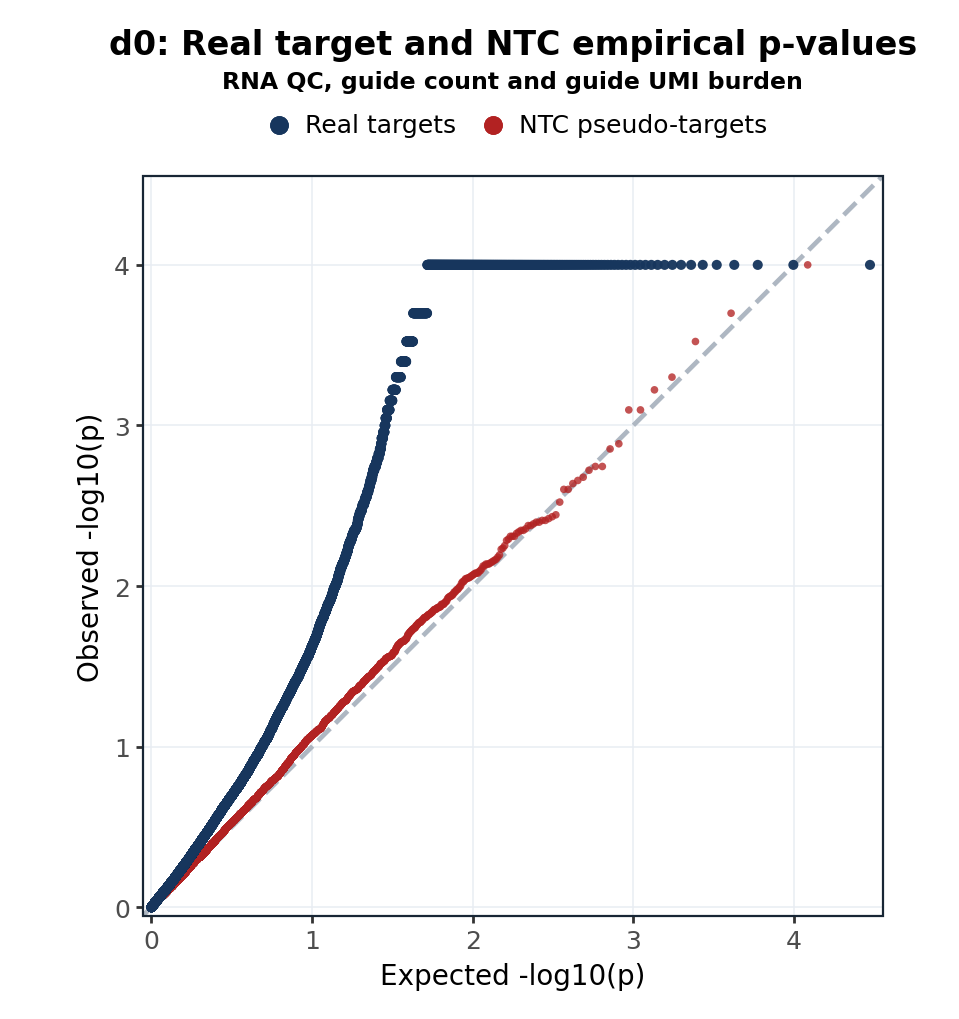

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


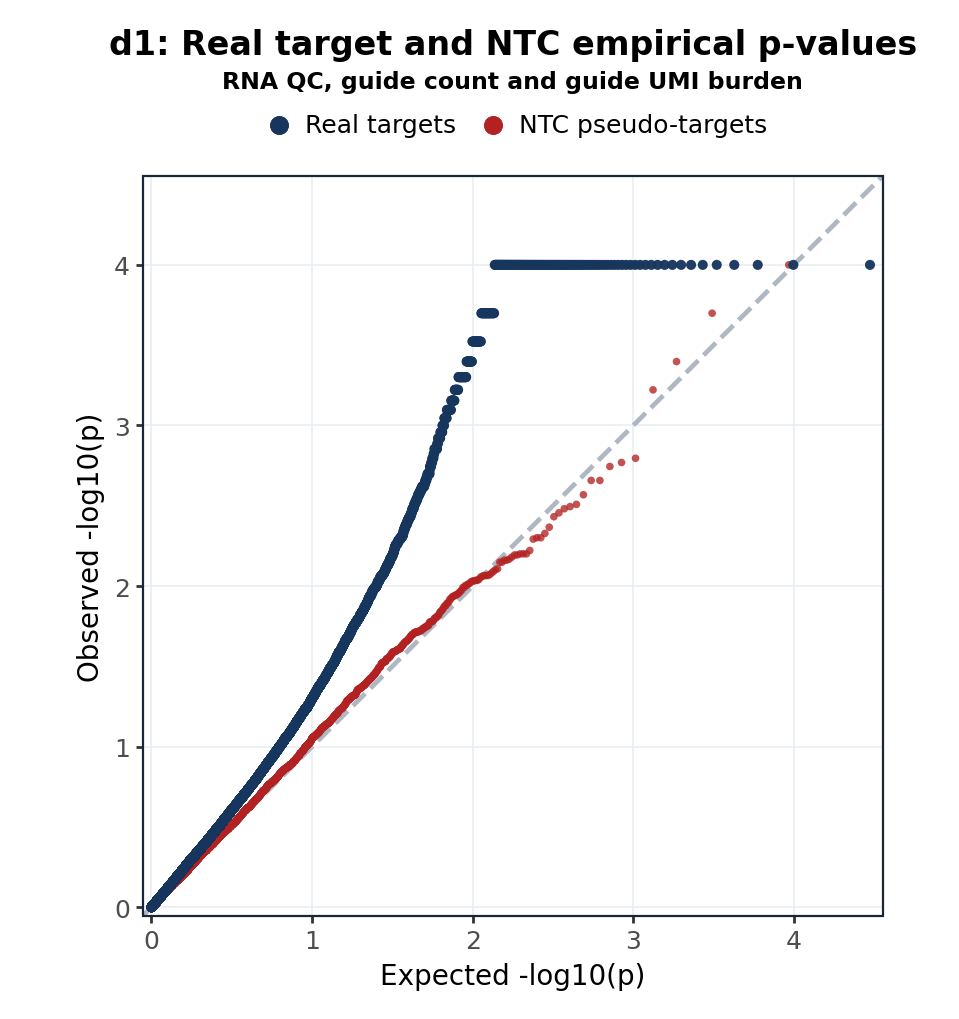

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


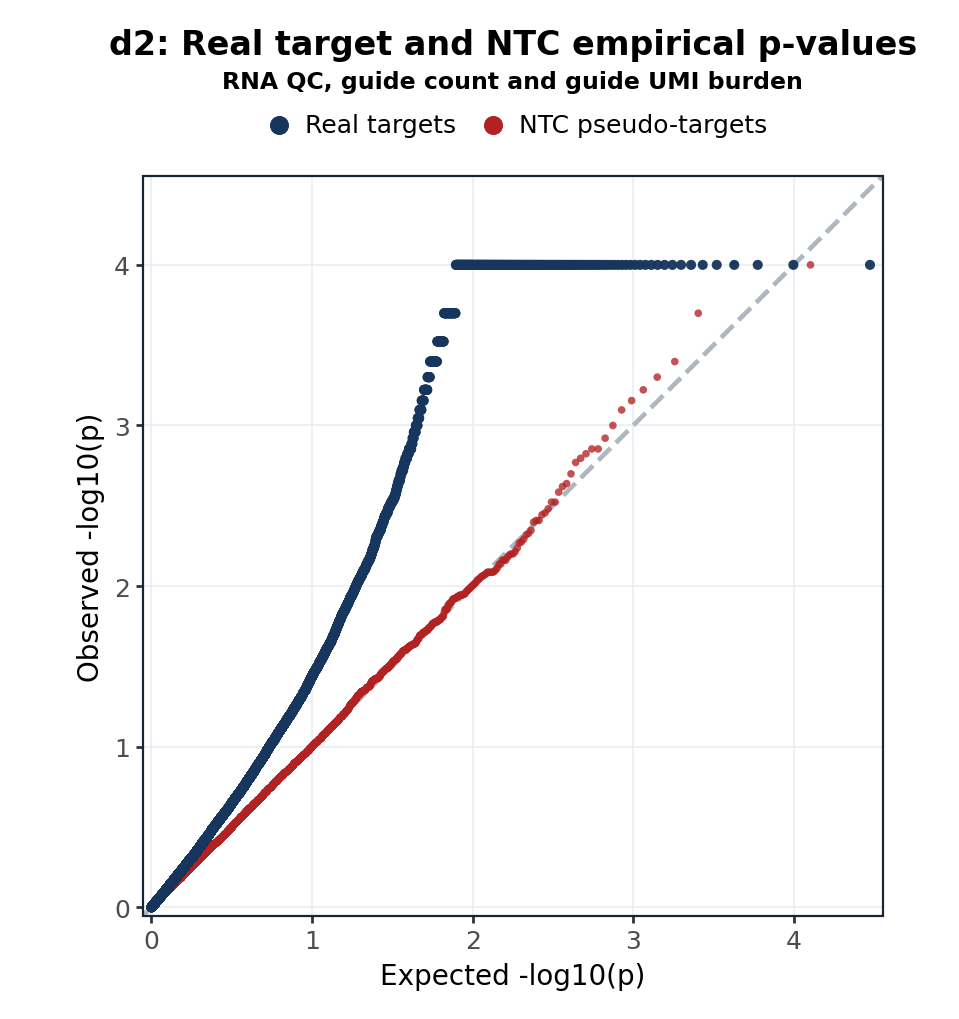

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


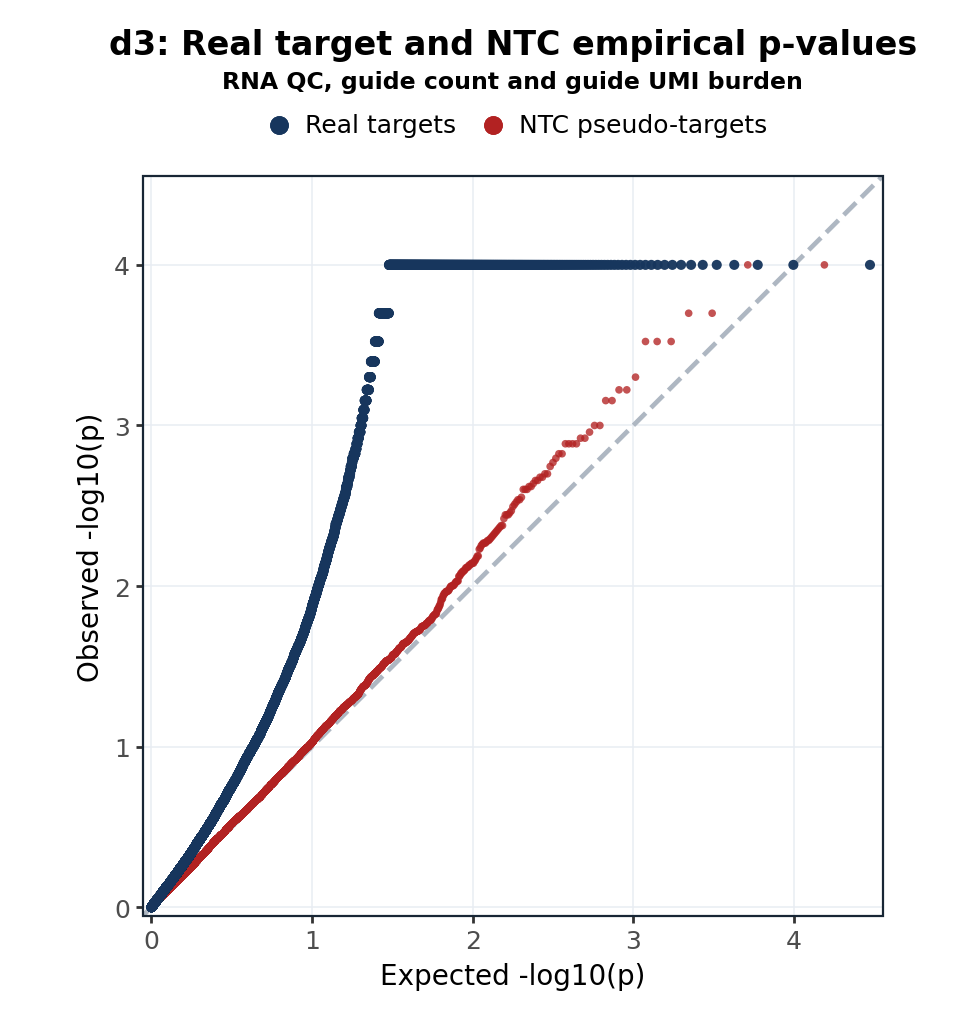

Saved files:

d0
  PDF: /scratch/users/edtng/cc_perturbseq_manuscript_figures/Figure_S04/panel_b/d0_QQ_full_covariates.pdf
  SVG: /scratch/users/edtng/cc_perturbseq_manuscript_figures/Figure_S04/panel_b/d0_QQ_full_covariates.svg
  EPS: /scratch/users/edtng/cc_perturbseq_manuscript_figures/Figure_S04/panel_b/d0_QQ_full_covariates.eps
  PNG: /scratch/users/edtng/cc_perturbseq_manuscript_figures/Figure_S04/panel_b/d0_QQ_full_covariates.png

d1
  PDF: /scratch/users/edtng/cc_perturbseq_manuscript_figures/Figure_S04/panel_b/d1_QQ_full_covariates.pdf
  SVG: /scratch/users/edtng/cc_perturbseq_manuscript_figures/Figure_S04/panel_b/d1_QQ_full_covariates.svg
  EPS: /scratch/users/edtng/cc_perturbseq_manuscript_figures/Figure_S04/panel_b/d1_QQ_full_covariates.eps
  PNG: /scratch/users/edtng/cc_perturbseq_manuscript_figures/Figure_S04/panel_b/d1_QQ_full_covariates.png

d2
  PDF: /scratch/users/edtng/cc_perturbseq_manuscript_figures/Figure_S04/panel_b/d2_QQ_full_covariates.pdf
  SVG: /scratch/users

In [3]:

illustrator_out_dir = PANEL_B_DIR

all_saved_files = {}

for day in DAYS:
    p, saved = plot_ipsc_ec_qq(
        qq_points,
        day=day,
        pvalue_type="empirical",
        title=f"{day}: Real target and NTC empirical p-values",
        subtitle="RNA QC, guide count and guide UMI burden",
        output_stem=illustrator_out_dir / f"{day}_QQ_full_covariates",
        formats=("pdf", "svg", "eps", "png"),
    )
    all_saved_files[day] = saved
    display(p)

print("Saved files:")
for day, files in all_saved_files.items():
    print(f"\n{day}")
    for fmt, path in files.items():
        print(f"  {fmt.upper()}: {path}")


## S4c — biological-replicate effect concordance

Target–program beta estimates are matched between biological replicates within each day. NTC rows and non-finite effects are removed. Each retained target must have at least 20 target-carrying cells represented in the original cNMF usage matrix in both replicates. Pooled full-day p values are BH-adjusted separately within each day across all finite real target–program tests, and matched effects are retained when pooled q ≤ 0.10.

The default selection uses skew-calibrated pooled p values. When skew-calibrated files are unavailable, the recorded empirical fallback is used. There is no effect-size trimming and no automatic top-N fallback.


,day,requested_pvalue_type,actual_pvalue_type,n_tests_for_bh,path,size_bytes,mtime_ns
0,d0,skew,skew,14900,/oak/stanford/groups/engreitz/Users/tri/CodeBa...,1252951,1793352861000000000
1,d1,skew,skew,14900,/oak/stanford/groups/engreitz/Users/tri/CodeBa...,1251444,1783373593000000000
2,d2,skew,skew,14900,/oak/stanford/groups/engreitz/Users/tri/CodeBa...,1251924,1783374970000000000
3,d3,skew,skew,14900,/oak/stanford/groups/engreitz/Users/tri/CodeBa...,1254530,1783377464000000000


,day,replicate_pair,matched_finite_real_pairs,with_pooled_pvalue,after_target_cell_filter,selected_pairs
0,d0,d0_rep1 vs d0_rep2,14900,14900,14900,903
1,d1,d1_rep1 vs d1_rep2,14900,14900,14850,279
2,d2,d2_rep1 vs d2_rep2,14900,14900,14900,522
3,d3,d3_rep1 vs d3_rep2,14900,14900,14850,1502


,day,replicate_pair,n_target_program_pairs,n_targets,n_programs,pearson_r,spearman_r,sign_agreement,min_pooled_pvalue,median_pooled_pvalue,max_pooled_pvalue,min_pooled_qvalue,median_pooled_qvalue,max_pooled_qvalue,facet_label
0,d0,d0_rep1 vs d0_rep2,903,209,50,0.877209,0.776758,0.997785,1.544930e-116,0.000512,0.006047,2.301946e-112,0.016889,0.099778,d0: d0_rep1 vs d0_rep2\nPearson r=0.88; Spearm...
1,d1,d1_rep1 vs d1_rep2,279,114,48,0.884598,0.771773,0.992832,2.331969e-24,0.000238,0.001871,3.474634e-20,0.025196,0.099935,d1: d1_rep1 vs d1_rep2\nPearson r=0.88; Spearm...
2,d2,d2_rep1 vs d2_rep2,522,154,49,0.895140,0.819837,0.994253,1.363362e-46,0.000362,0.003493,2.031410e-42,0.020641,0.099711,d2: d2_rep1 vs d2_rep2\nPearson r=0.90; Spearm...
3,d3,d3_rep1 vs d3_rep2,1502,261,50,0.916577,0.865787,0.996671,1.000000e-250,0.000632,0.010058,7.450000e-247,0.012518,0.099773,d3: d3_rep1 vs d3_rep2\nPearson r=0.92; Spearm...


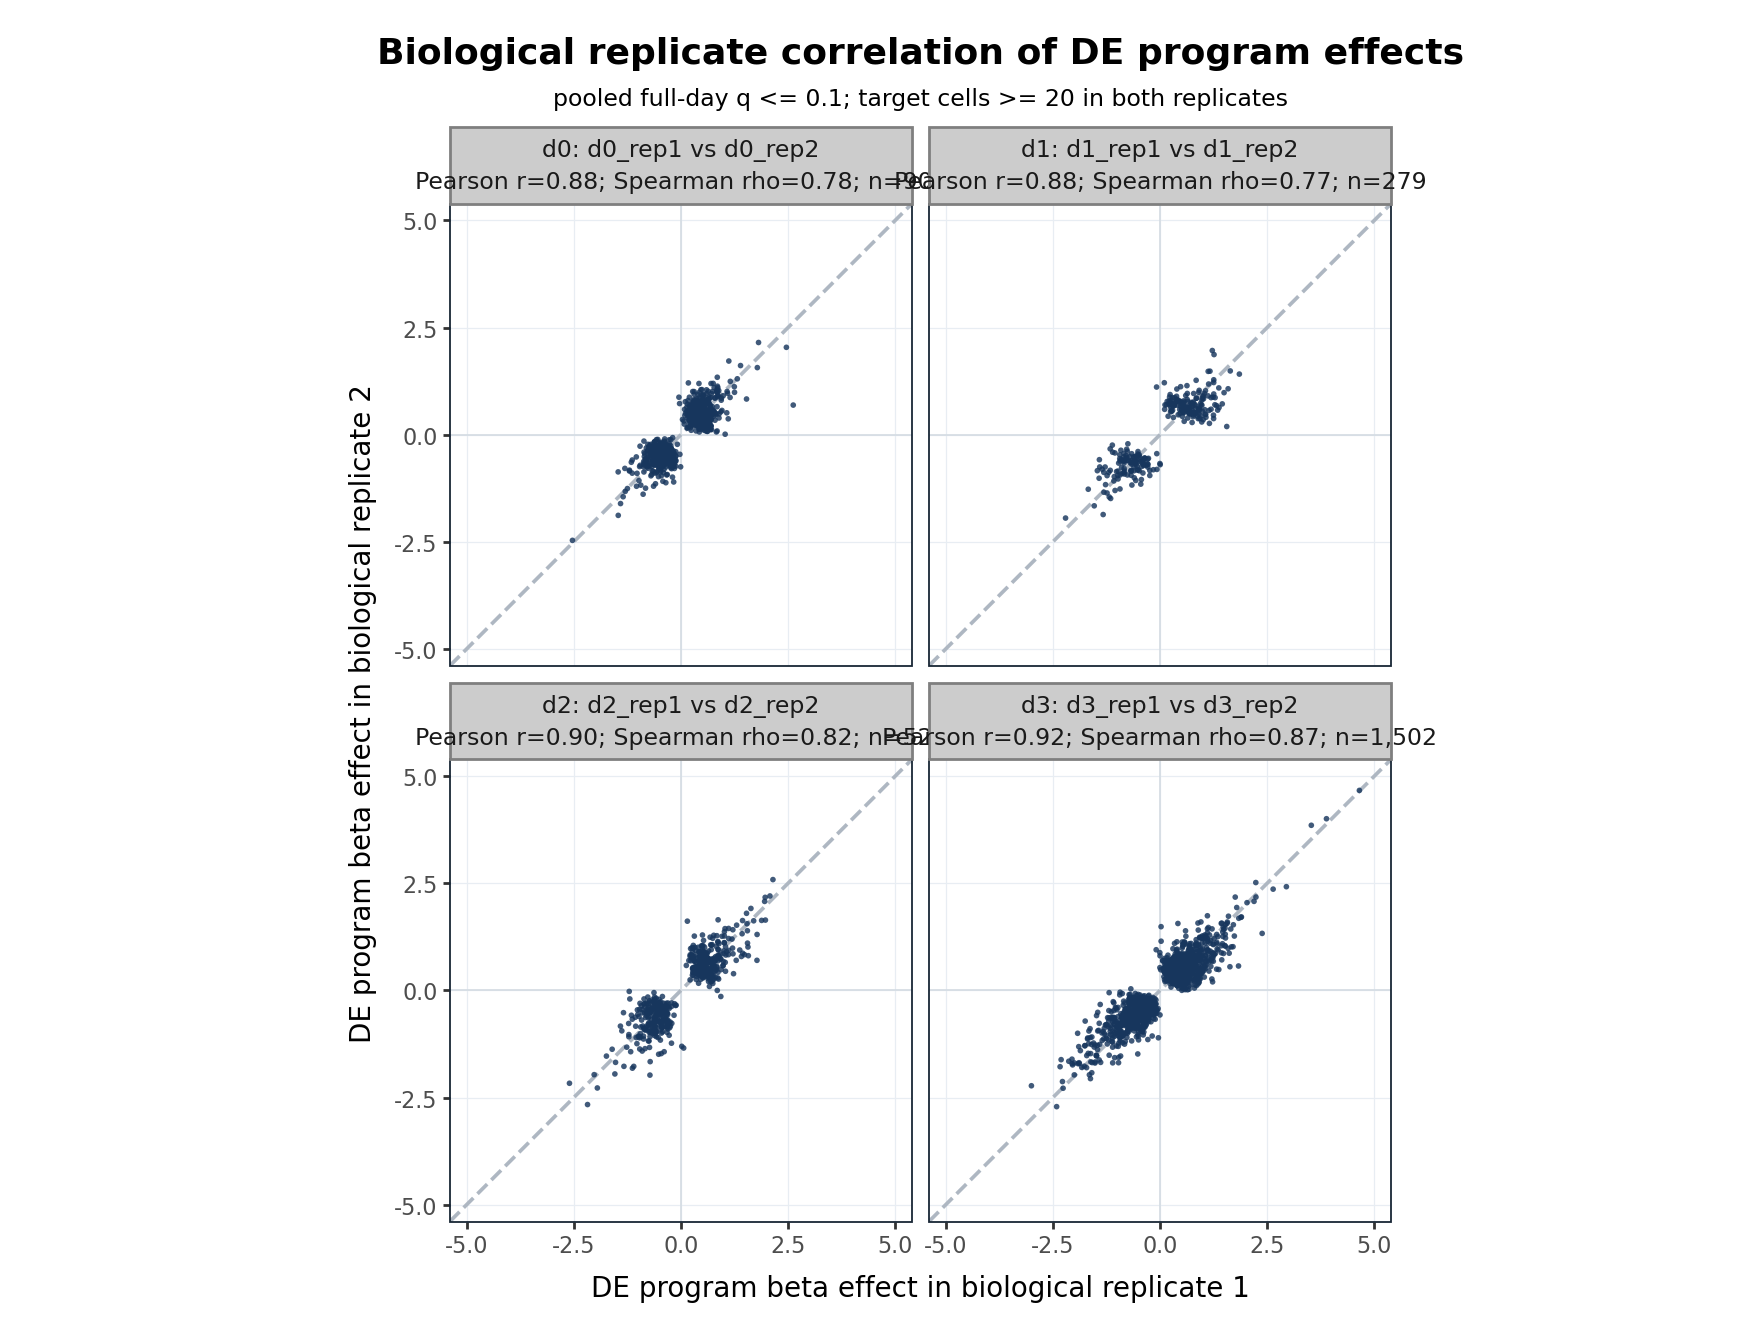

Selected S4c outputs: /scratch/users/edtng/cc_perturbseq_manuscript_figures/Figure_S04/panel_c
Use the pooled_selected_* figures, not any unfiltered figures from an older run.


In [4]:
# Source executed notebook cells 29-31: post-CRT filtering, not a new CRT.
from cc_perturbseq.figure_s04_postcrt import (
    load_or_rebuild_target_counts, read_pooled_results,
    select_effect_pairs, render_selected_effects,
)
PLOT_OUT_DIR = PANEL_C_DIR
unfiltered_effects = build_effect_pair_table(manifest)
unfiltered_path = PANEL_C_DIR / "S4c_unfiltered_real_effect_pairs.csv"
unfiltered_effects.to_csv(unfiltered_path, index=False)

target_counts = load_or_rebuild_target_counts(
    INPUT_MODEL_ROOT, DAYS, PANEL_C_DIR,
    counts_csv=TARGET_COUNTS_CSV,
    mapping_policy=GUIDE_MAPPING_POLICY,
)
pooled, pooled_inputs = read_pooled_results(
    INPUT_MODEL_ROOT, DAYS, preferred=POOLED_PVALUE_TYPE,
)
pooled.to_csv(PANEL_C_DIR / "S4c_pooled_full_day_pvalues_and_qvalues.csv", index=False)
pooled_inputs.to_csv(PANEL_C_DIR / "S4c_pooled_pvalue_input_audit.csv", index=False)
selected, all_pairs_audit, filter_summary = select_effect_pairs(
    unfiltered_effects, pooled, target_counts,
    q_cutoff=POOLED_Q_CUTOFF, min_target_cells=MIN_TARGET_CELLS_PER_REP,
)
all_pairs_audit.to_csv(PANEL_C_DIR / "S4c_filter_audit.csv", index=False)
filter_summary.to_csv(PANEL_C_DIR / "S4c_filter_counts.csv", index=False)
display(pooled_inputs)
display(filter_summary)
# Never silently replace an empty selection with an unfiltered or top-N panel.
effects, summary, combined_plot = render_selected_effects(
    selected, PANEL_C_DIR,
    q_cutoff=POOLED_Q_CUTOFF, min_target_cells=MIN_TARGET_CELLS_PER_REP,
)
display(summary)
display(combined_plot)
selection_tag = (
    f"q_q{str(POOLED_Q_CUTOFF).replace('.', '_')}_top500_mincells{MIN_TARGET_CELLS_PER_REP}"
)
# The source filename includes top500 even though SELECTION_MODE='q'; no fallback runs.
selection_settings_path = PANEL_C_DIR / "S4c_selection_settings.json"
selection_settings_path.write_text(json.dumps({
    "source_executed_notebook_cells": [29, 30, 31],
    "selection_mode": "q", "pooled_q_cutoff": POOLED_Q_CUTOFF,
    "min_target_cells_per_replicate": MIN_TARGET_CELLS_PER_REP,
    "pooled_pvalue_requested": POOLED_PVALUE_TYPE,
    "pooled_pvalue_inputs": pooled_inputs.to_dict("records"),
    "counts_definition": "unique target carriers whose IDs occur in original cNMF usage, each replicate",
    "bh_family": "all finite real target-program tests separately within day, before pair/count filters",
    "no_crt_rerun_required_for_selection": True,
    "historical_counts_are_diagnostic_only": True,
}, indent=2) + "\n")
# Exact outputs from this execution, rather than stale old figures in panel_c/.
selected_output_files = [
    unfiltered_path,
    PANEL_C_DIR / "DIAGNOSTIC_target_cell_counts_by_replicate.csv",
    PANEL_C_DIR / "target_cell_count_provenance.json",
    PANEL_C_DIR / "S4c_pooled_full_day_pvalues_and_qvalues.csv",
    PANEL_C_DIR / "S4c_pooled_pvalue_input_audit.csv",
    PANEL_C_DIR / "S4c_filter_audit.csv",
    PANEL_C_DIR / "S4c_filter_counts.csv",
    selection_settings_path,
    PANEL_C_DIR / f"pooled_selected_replicate_effect_pairs_{selection_tag}.csv",
    PANEL_C_DIR / f"pooled_selected_replicate_effect_correlation_summary_{selection_tag}.csv",
]
stems = [f"pooled_selected_biological_replicate_DE_program_effect_correlation_all_days_{selection_tag}"]
stems += [f"{day}_pooled_selected_biological_replicate_DE_program_effect_correlation_{selection_tag}"
          for day in effects["day"].drop_duplicates()]
selected_output_files += [PANEL_C_DIR / f"{stem}.{suffix}"
                          for stem in stems for suffix in ("pdf", "svg", "png")]
print("Selected S4c outputs:", PANEL_C_DIR)
print("Use the pooled_selected_* figures, not any unfiltered figures from an older run.")


In [5]:
for panel in ("b", "c"):
    if panel == "b":
        files = [Path(p) for day_outputs in all_saved_files.values() for p in day_outputs.values()]
        files.append(PANEL_B_DIR / "all_days_QQ_points.csv")
    else:
        files = selected_output_files
    if not any(p.suffix == ".svg" and p.is_file() for p in files):
        raise RuntimeError(f"Panel {panel}: no SVG output from this execution")
    write_receipt(
        ctx, panel, status="RESCRIPTED_NUMERICAL_INPUTS_RENDERED",
        inputs={"qq_points": str(qq_csv), "replicate_manifest": str(manifest_path)},
        outputs={p.name: str(p) for p in files if p.is_file()},
        parameters={
            "runtime_source_notebook_required": False,
            "recomputed_crt": RECOMPUTE_CRT,
            "source_style_changed": False,
            "panels": ["b", "c"],
            "s4c_selection": "executed source cells 29-31; pooled q and target-cell support",
            "selection_settings": str(selection_settings_path),
        },
    )
